### Intro
This notebook contains an example of the **differentiable physics** approach to sound field reconstruction described in:

S. A. Verburg, E. Fernandez-Grande, P. Gerstoft, *Differentiable physics for sound field reconstruction*, J. Acoust. Soc. Am. 158, 5 (2025).

Samuel A. Verburg. saveri@dtu.dk.

We start with the imports. You can run the code on CPU or GPU.

In [1]:
from pathlib import Path

import torch
import numpy as np
import diffsfr
from diffsfr.utils import scale_domain, make_tensor, make_xyt_tensor, Grid
from diffsfr.fields import SoundField
from diffsfr.sensors import SensorArray
from diffsfr.pinn import PINN
from diffsfr.dpnn import DPNN
from diffsfr.plots import *

# examples/ folder of the repository (requires `pip install -e .`), so the notebook
# runs from any working directory
examples_dir = Path(diffsfr.__file__).resolve().parents[2] / "examples"

device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print(f"Using {device} device") 

Using cpu device


### Background
Soundfield reconstruction involves estimating an acoustic pressure field over time and space from a limited number of spatially distributed observations. The reconstruction can be formulated as solving the following optimization problem
\begin{aligned}
&\min_{\boldsymbol{\theta}} \{\mathcal{L}_\text{data}\left(p(\mathbf{r},t_0; \boldsymbol{\theta}), \dots, p(\mathbf{r},t_{N-1}; \boldsymbol{\theta})\right) +\mathcal{L}_\text{sp}(p(\mathbf{r},t_0; \boldsymbol{\theta})) \}\\
& \textrm{subject to} \\
& \mathcal{D}[p(\mathbf{r},t;\boldsymbol{\theta})] = 0 \ \textrm{in} \  \Omega \times [0, T]\\
& \mathcal{B}[p(\mathbf{r},t;\boldsymbol{\theta})] = 0 \ \textrm{in} \  \partial\Omega \times [0, T],
\end{aligned}

where 
$$
\mathcal{D}[p] := \nabla^2 p(\mathbf{r},t) - \frac{1}{c^2}\frac{\partial^2 p(r,t)}{\partial t^2} = 0,
$$
is a differential operator expressing the acoustic wave equation, and
$$
\mathcal{B}[p] := \nabla p(\mathbf{r},t) \cdot \mathbf{n} +\frac{1}{c}\frac{\partial p}{\partial t} = 0 \quad \text{at} \ \mathbf{r}\in \partial\Omega,
$$
represents a given boundary condition (here, we consider a first-order absorptive boundary).
The loss function in the optimization problem consists of two terms. The first is a data-fitting term
$$
\mathcal{L}_\text{data}\left(p(\mathbf{r},t_0; \boldsymbol{\theta}), \dots, p(\mathbf{r},t_{n-1}; \boldsymbol{\theta})\right) = 
\frac{1}{M_\text{ob}N}\sum_{m=0}^{M_\text{ob}-1}\sum_{n=0}^{N-1} \left| p(\mathbf{r}_m,t_n; \boldsymbol{\theta}) - \hat{p}_{mn} \right|^2,
$$
where 
\begin{aligned}
\hat{p}_{mn} = p(\mathbf{r}_m, t_n) + e_{mn} \quad \text{for} \ m & =0,\dots,M_\text{ob}-1 \\ \text{and} \ n & =0,\dots,N-1,
\end{aligned}
are the noisy observations, $\mathbf{r}_0, \dots, \mathbf{r}_{M_\text{ob}-1}$ are the sensor locations, $t_0, \dots, t_{N-1}$ are the time samples, and $e_{mn}$ is additive noise.

The second term in the loss function is a sparsity constraint applied to the initial pressure,
$$
\mathcal{L}_\text{sp}(p(\mathbf{r},t_0; \boldsymbol{\theta})) = \frac{1}{M_\text{sp}}\sum_{m=0}^{M_\text{sp}-1} \left| p(\mathbf{r}_m,t_0; \boldsymbol{\theta}) \right| = \| \mathbf{p}_\text{sp}^0 \|_1 / M_\text{sp},
$$
where $\mathbf{r}_0,\dots,\mathbf{r}_{M_\text{sp}-1}$ are collocation points sampled over space, and $\mathbf{p}_\text{sp}^0 \in \mathbb{R}^{M_\text{sp}}$ represents the vector of pressure values at the these points. The minimization of $\mathcal{L}_\text{sp}$ promotes a sparse initial pressure in the $\ell_1$-norm sense, resulting in an optimization problem reminiscent of the Lasso regression.

In this notebook, we will compare two different physics-informed deep learning approaches to solve the reconstruction problem. 

### Setting up the problem

We start by defining a square 2D+1 domain of side length 1 m, max time 1 ms and sound speed 343 m/s. It is usually a good idea to scale it.

We also set a name for the initial condition, `ic_type = "twenty_pulses"` in this case, and create an instance of the class `SoundField`. Here we are loading a precomputed soundfield used in the example, but you can make your own (see class definition in fields.py). The only thing you need is an numpy array `soundfield.p` of size `n_L, n_L, n_T`.

Then we define the sensor distribution (e.g. a microphone array) for the observed data. We add noise with a given SNR, define the number of sensors, and also a downsampling factor. We use this `factor` to downsample the grid in which we originally computed `soundfield`, and we will use the downsampled grid for the differentiable physics solver (more on that later). 

The class `SensorArray` is a container for the sensor distribution and observed data. `array.get_positions(grid)` finds positions that coincide with cells in the downsampled grid to create the sensor distribution. You can also define you own (see class definition in sensors.py). 

Finally, we plot the soundfield and data. 


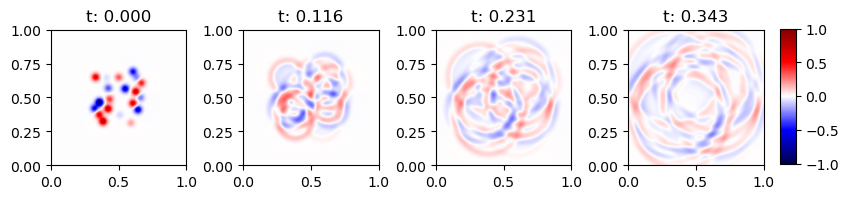

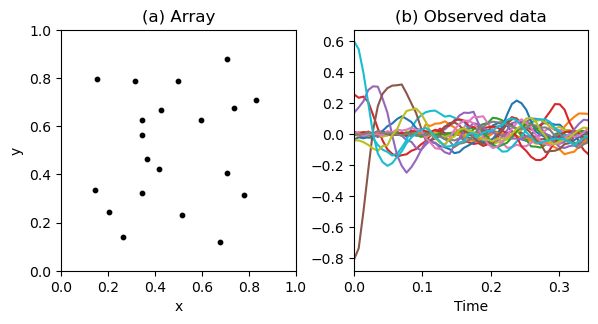

In [2]:
L, T, c = scale_domain(L=1, T=1e-3, c=343)
n_L = 199
n_T = 99
x = np.linspace(0, L, n_L)
y = np.linspace(0, L, n_L)
t = np.linspace(0, T, n_T)
xx, yy = np.meshgrid(x, y)
xy = np.column_stack((xx.ravel(), yy.ravel()))
grid = Grid(xx, yy, t, xy)

ic_type = "twenty_pulses"
data_dir = examples_dir / "data"
fig_dir = examples_dir / "figures" / ic_type
model_dir = examples_dir / "models" / ic_type
soundfield = SoundField(L, T, c, ic_type=ic_type, grid=grid)
soundfield = soundfield.load(data_dir)

snr = 20
num_mics = 20
factor = int(2)  # downsampling from reference grid to DPNN grid

grid = soundfield.grid.downsample(factor=factor)
array = SensorArray(n=num_mics, distribution='pseudo_random', L_min=0.1*L, L_max=0.9*L, min_distance=0.05, snr=snr)
array.get_positions(grid)
array.get_data(soundfield, factor=factor)

plot_field(soundfield.p, L, T, figname=fig_dir / 'true_field.pdf', show=True)
plot_data(array.data, array.xy, L, T, figname=fig_dir / 'data.pdf', show=True)

In [3]:
# Make everything that needs to be a torch tensor a torch tensor
grid.xyt = make_xyt_tensor(grid.xy, grid.t, device)
grid.xy = make_tensor(grid.xy, device)
array.xyt = make_xyt_tensor(array.xy, array.t, device)
array.data = make_tensor(array.data, device)
soundfield.grid.xyt = make_xyt_tensor(soundfield.grid.xy, soundfield.grid.t, device)

### PINN
The first model we will use to solve the reconstruction problem is a physics-informed neural network.

PINNs approximate the entire solution to the PDE with a neural network, $p_\text{pinn}(\mathbf{r},t;\boldsymbol{\theta})$. The network inputs are position $\mathbf{r} \in \Omega$ and time $t \in [0, T]$, and the output is pressure. 
To train the PINN, the problem is formulated as the unconstrained optimization problem
\begin{aligned}
    \min_{\boldsymbol{\theta}} \ \{ & \lambda_\text{data} \mathcal{L}_\text{data}(p_\text{pinn}(\mathbf{r},t_0;\boldsymbol{\theta}),\dots,p_\text{pinn}(\mathbf{r},t_{N-1};\boldsymbol{\theta})) + \\
    & \lambda_\text{sp} \mathcal{L}_\text{sp}^\text{(e)}(p_\text{pinn}(\mathbf{r},t;\boldsymbol{\theta})) +
    \lambda_\text{pde} \mathcal{L}_\text{pde}(p_\text{pinn}(\mathbf{r},t;\boldsymbol{\theta})) + \\
    & \lambda_\text{bcs} \mathcal{L}_\text{bcs}(p_\text{pinn}(\mathbf{r},t;\boldsymbol{\theta})) \}, 
\end{aligned}
where the PDE is introduced through the soft penalty
$$
\mathcal{L}_\text{pde}(p_\text{pinn}(\mathbf{r},t;\boldsymbol{\theta})) = \frac{1}{M_\text{pde}}\sum_{m=0}^{M_\text{pde}-1} \left| \mathcal{D}[p_\text{pinn}(\mathbf{r}_m,t_m;\boldsymbol{\theta})] \right|^2, 
$$
and $(\mathbf{r}_m, t_m) \in \Omega\times[0,T]$, $m=0,\dots,M_\text{pde}-1$ are collocation points stochastically sampled at each training iteration.
Similarly, the boundary condition is introduced through the penalty
$$
\mathcal{L}_\text{bcs}(p_\text{pinn}(\mathbf{r},t;\boldsymbol{\theta})) = \frac{1}{M_\text{bcs}}\sum_{m=0}^{M_\text{bcs}-1} \left| \mathcal{B}[p_\text{pinn}(\mathbf{r}_m,t_m;\boldsymbol{\theta})] \right|^2, 
$$
where $(\mathbf{r}_m, t_m) \in \partial\Omega\times[0,T]$, i.e, the collocation points $\mathbf{r}_m$ are sampled on the boundaries only. Automatic differentiation is used to evaluate the partial derivatives of the network's output with respect to its inputs at the collocation points, and thus calculate $\mathcal{L}_\text{pde}$ and $\mathcal{L}_\text{bcs}$.

We create an instance of the class `PINN`. The architecture is a simple MLP with sine activations (see pinn.py). There are some useful functions to train, save and load the model. We use an annealing algorithm to select the weighting parameters $\lambda_\text{data}, \lambda_\text{sp}, \lambda_\text{pde},$ and $\lambda_\text{bcs}$, which will be updated every `update_rate` epochs.

Once the PINN is trained, it can be queried at any $x,y,t$. We pass on the original grid and plot the estimated field.

100%|██████████| 10/10 [00:02<00:00,  3.74it/s]
C:\Users\saveri\Documents\GitHub\differentiable-soundfield-reconstruction\src\diffsfr\pinn.py:130: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this expe

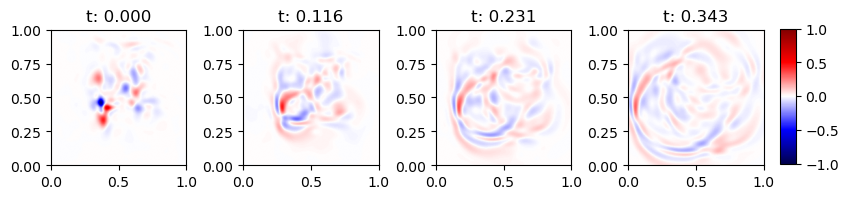

In [4]:
# PINN training
pinn = PINN(L, T, c, num_layers=4, num_hidden=128, device=device)
pinn.train(array, n_epochs=int(1e1), update_rate=100) # runing 1000 epochs for demo purposes
# pinn.save_nn(model_dir) 
pinn.load_nn(model_dir, device) # load pretrained model

# PINN inference
pinn.compute_field(soundfield.grid)
plot_field(pinn.p, L, T, figname=fig_dir / 'pinn.pdf', show=True)

### Differentiable physics 
In the proposed DP approach a neural network $g_\text{dp}(\mathbf{r};\boldsymbol{\theta})$ models the unknown initial pressure, and not the entire PDE solution (like PINNs do). The physical constraints are imposed by applying a numerical PDE solver to the network output, instead of using autograd to compute the differential operators (like PINNs do). Training the DP neural network amounts to solving the optimization problem 
$$
\min_{\boldsymbol{\theta}} \ \left\{ \lambda_\text{data} \mathcal{L}_\text{data}^{\text{(d)}}(\mathbf{p}^0,\mathbf{p}^1\dots, \mathbf{p}^{N-1}) + \lambda_\text{reg} \mathcal{L}_\text{reg}(g_\text{dp}(\mathbf{r};\boldsymbol{\theta})) \right\}, 
$$
where $\mathbf{p}^1,\dots, \mathbf{p}^{N-1}$ is the numerical solution of the PDE computed in a $M_\text{grid}$-dimensional discretization grid, and $\mathbf{p}^0$ is obtained by sampling the neural network $g_\text{dp}(\mathbf{r};\boldsymbol{\theta})$ at the grid positions. Therefore, $\mathbf{p}^n$ is a vector in $\mathbb{R}^{M_\text{grid}}$ instead of being a continuous function. 

The data fitting function, $\mathcal{L}_\text{data}^{\text{(d)}}$, that operates on the discrete pressure is expressed as
\begin{aligned}
     & \mathcal{L}_\text{data}^{\text{(d)}}\left(\mathbf{p}^0, \dots, \mathbf{p}^{N-1}\right) = \\
    & \frac{1}{M_\text{ob}N}\left( \left\| \mathbf{M} \mathbf{p}^{0}(\boldsymbol{\theta}) - \hat{\mathbf{p}}^0 \right\|^2 + \sum_{n=1}^{N-1} \left\| \mathbf{M} \mathbf{p}^{n}(\mathbf{p}^{0}(\boldsymbol{\theta})) - \hat{\mathbf{p}}^n \right\|^2 \right),
\end{aligned}

where $\mathbf{M}$ is a $M_\text{ob}\times M_\text{grid}$ binary matrix that extracts the pressure values at the observation positions, and $\hat{\mathbf{p}}^n \in \mathbb{R}^{M_\text{ob}}$ denotes the observations arranged as a vector.

In our approach, we use a simple Finite Difference Time Domain (FDTD) numerical solver with explicit time integration, 

\begin{align}
    &\mathbf{p}^{1} = \mathbf{p}^{0} + 0.5 \mathbf{L} \mathbf{p}^{0}, \ \text{and}\\
    &\mathbf{p}^{n+1} = 2\mathbf{p}^{n} - \mathbf{p}^{n-1} + \mathbf{L} \mathbf{p}^{n}, \ \text{for} \ n = 1,\dots,N-1,
\end{align}
where $\mathbf{L} = (c \Delta t / \Delta r)^2 \mathbf{L}_\Delta$ and $\mathbf{L}_\Delta \in \mathbb{R}^{M_\text{grid}\times M_\text{grid}}$ is the central difference approximation of the Laplace operator $\nabla^2[\cdot]$. 

We create an instance of the class `DPNN`. The architecture is also a MLP with sine activations (see dpnn.py). 
For training the DPNN we also need to provide the grid that the numerical solver will use during training (which in this case is the downsampled version of the original grid, as defined when we set up the problem). A stability check is performed to ensure that the provided grid spacing will result in a stable finite-difference computation. 

Once the DPNN is trained, it can be queried on a higher resolution grid. This is an important feature of the DPNN approach, because even if it trained with a fixed grid, the underlying initial pressure is represented by a continuous function (the neural network), so that the solution can easily be upscaled.

100%|██████████| 10/10 [00:00<00:00, 35.43it/s]
C:\Users\saveri\Documents\GitHub\differentiable-soundfield-reconstruction\src\diffsfr\dpnn.py:147: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this expe

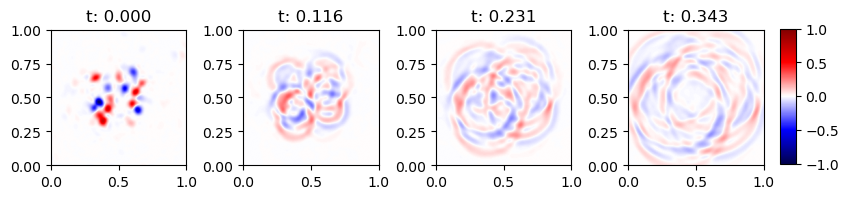

In [5]:
# DPNN training
dpnn = DPNN(L, T, c, device=device, gradient="operator")
dpnn.train(array, grid, n_epochs=int(1e1), update_rate=100) 
# dpnn.save_nn(model_dir)
dpnn.load_nn(model_dir, device)

# DPNN inference
soundfield.grid.xy = make_tensor(soundfield.grid.xy, device)
dpnn.compute_field(soundfield.grid)
dpnn.p = dpnn.p.cpu().detach().numpy()
plot_field(dpnn.p, L, T, figname=fig_dir / 'dpnn.pdf', show=True)

Finally, we can compare the training dynamics and solutions. 

C:\Users\saveri\Documents\GitHub\differentiable-soundfield-reconstruction\src\diffsfr\plots.py:85: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[0, 1].legend(loc="upper right")
C:\Users\saveri\Documents\GitHub\differentiable-soundfield-reconstruction\src\diffsfr\plots.py:108: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[1, 1].legend(loc="upper right")


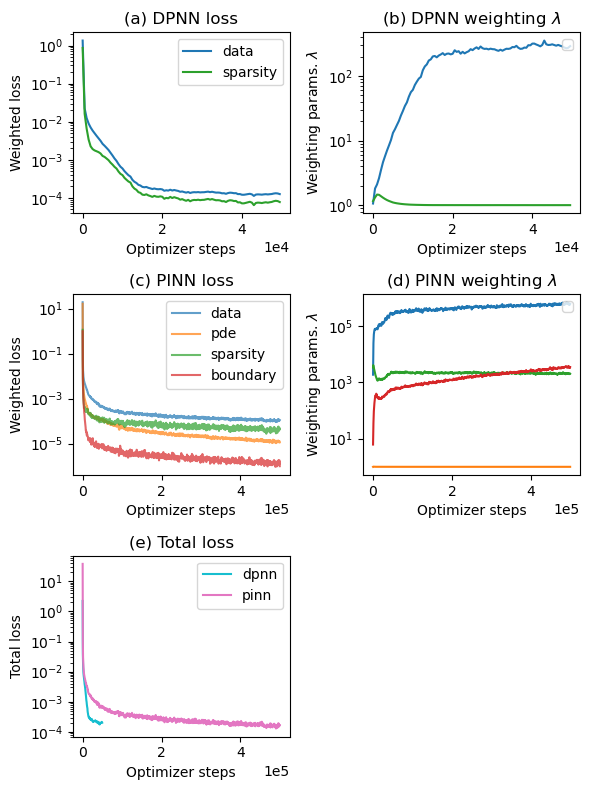

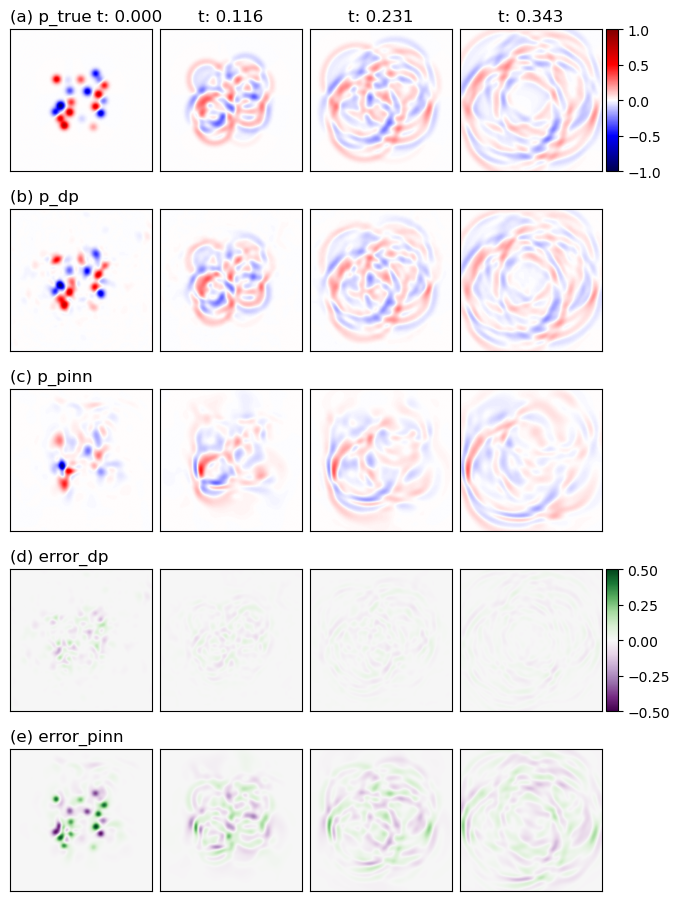

In [6]:
# Plots
plot_train_log(pinn, dpnn, label_pinn=['data', 'pde', 'sparsity', 'boundary'], label_dpnn=['data', 'sparsity'], figname=fig_dir / 'train_log.pdf', show=True)
plot_compare_field(soundfield.p, pinn.p, dpnn.p, soundfield.grid.t, soundfield.grid.n_T, L, soundfield.grid.n_L, figname=fig_dir / 'compare_field.pdf', show=True)
animate_comparison(soundfield.p, pinn.p, dpnn.p, L, figname=fig_dir / 'animation.gif')